# Analysis of Parallel TQFM Training Results (Moon Dataset)

This notebook analyzes results from parallel_losses_moon.py training runs.

In [1]:
import sys
import os
sys.path.append(os.path.join(os.path.dirname(os.getcwd())))

import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [2]:
# Configuration
results_dir = Path('../results_losses_circle_loglik_from_Eff_noisy')
depths = [1, 2, 3, 4, 5, 6]
loss_types = ['hilbert_schmidt', 'pre_determine_inner', 'log_likelihood_macro']
labels = {
    'hilbert_schmidt': 'Hilbert Schmidt', 
    'pre_determine_inner': 'Inner Product', 
    'log_likelihood_macro': 'Log Likelihood'
}
colors = {
    'hilbert_schmidt': 'blue', 
    'pre_determine_inner': 'green', 
    'log_likelihood_macro': 'orange'
}

## 1. Load Results from PKL and JSON Files

In [3]:
# Load all results
depth_results = {}

for depth in depths:
    depth_results[depth] = {loss_type: [] for loss_type in loss_types}
    
    for loss_type in loss_types:
        # Find all pkl files for this depth and loss type
        pattern = f'tqfm_{loss_type}_depth{depth}_*.pkl'
        pkl_files = sorted(results_dir.glob(pattern))
        
        for pkl_file in pkl_files:
            try:
                with open(pkl_file, 'rb') as f:
                    tqfm = pickle.load(f)
                
                if tqfm.best_params is None:
                    continue
                
                # Extract metrics
                final_loss = tqfm.loss_history[-1] if tqfm.loss_history else None
                train_acc = tqfm.train_accuracy_history[-1] if tqfm.train_accuracy_history else None
                
                depth_results[depth][loss_type].append({
                    'file': pkl_file.name,
                    'tqfm': tqfm,
                    'final_loss': final_loss,
                    'train_acc': train_acc,
                    'loss_history': tqfm.loss_history,
                    'train_acc_history': tqfm.train_accuracy_history
                })
            except Exception as e:
                print(f"Error loading {pkl_file.name}: {e}")

# Print summary
print("Loaded Results Summary:")
print("="*60)
for depth in depths:
    print(f"\nDepth {depth}:")
    for loss_type in loss_types:
        n_runs = len(depth_results[depth][loss_type])
        print(f"  {labels[loss_type]}: {n_runs} runs")

Loaded Results Summary:

Depth 1:
  Hilbert Schmidt: 0 runs
  Inner Product: 0 runs
  Log Likelihood: 0 runs

Depth 2:
  Hilbert Schmidt: 0 runs
  Inner Product: 0 runs
  Log Likelihood: 0 runs

Depth 3:
  Hilbert Schmidt: 0 runs
  Inner Product: 0 runs
  Log Likelihood: 0 runs

Depth 4:
  Hilbert Schmidt: 0 runs
  Inner Product: 0 runs
  Log Likelihood: 20 runs

Depth 5:
  Hilbert Schmidt: 0 runs
  Inner Product: 0 runs
  Log Likelihood: 0 runs

Depth 6:
  Hilbert Schmidt: 0 runs
  Inner Product: 0 runs
  Log Likelihood: 0 runs


In [4]:
# Load JSON files with test accuracies
json_results = {}

for depth in depths:
    json_results[depth] = []
    
    # Find all json files for this depth
    pattern = f'training_times_depth{depth}_*.json'
    json_files = sorted(results_dir.glob(pattern))
    
    for json_file in json_files:
        try:
            with open(json_file, 'r') as f:
                data = json.load(f)
                json_results[depth].append(data)
        except Exception as e:
            print(f"Error loading {json_file.name}: {e}")

# Print summary of JSON results
print("\nJSON Results (with test accuracies):")
print("="*60)
for depth in depths:
    n_files = len(json_results[depth])
    print(f"Depth {depth}: {n_files} JSON files")
    
    if json_results[depth] and 'test_accuracies' in json_results[depth][0]:
        print("  Test accuracies available")


JSON Results (with test accuracies):
Depth 1: 0 JSON files
Depth 2: 0 JSON files
Depth 3: 0 JSON files
Depth 4: 20 JSON files
  Test accuracies available
Depth 5: 0 JSON files
Depth 6: 0 JSON files


## 2. Calculate Statistics

In [5]:
# Calculate mean and std for each depth and loss type
stats = {}

for depth in depths:
    stats[depth] = {}
    
    for loss_type in loss_types:
        runs = depth_results[depth][loss_type]
        
        if not runs:
            continue
        
        losses = [r['final_loss'] for r in runs if r['final_loss'] is not None]
        train_accs = [r['train_acc'] for r in runs if r['train_acc'] is not None]
        
        # Get test accuracies from JSON files
        test_accs = []
        for json_data in json_results[depth]:
            if 'test_accuracies' in json_data and json_data['test_accuracies']:
                test_acc = json_data['test_accuracies'].get(loss_type)
                if test_acc is not None:
                    test_accs.append(test_acc)
        
        stats[depth][loss_type] = {
            'mean_loss': np.mean(losses) if losses else None,
            'std_loss': np.std(losses) if losses else None,
            'mean_train_acc': np.mean(train_accs) if train_accs else None,
            'std_train_acc': np.std(train_accs) if train_accs else None,
            'mean_test_acc': np.mean(test_accs) if test_accs else None,
            'std_test_acc': np.std(test_accs) if test_accs else None,
            'n_runs': len(runs),
            'n_test_runs': len(test_accs)
        }

# Display as DataFrame
rows = []
for depth in depths:
    for loss_type in loss_types:
        if loss_type in stats[depth]:
            s = stats[depth][loss_type]
            rows.append({
                'Depth': depth,
                'Loss Function': labels[loss_type],
                'Mean Loss': f"{s['mean_loss']:.4f} ± {s['std_loss']:.4f}" if s['mean_loss'] else 'N/A',
                'Train Acc': f"{s['mean_train_acc']*100:.2f}% ± {s['std_train_acc']*100:.2f}%" if s['mean_train_acc'] else 'N/A',
                'Test Acc': f"{s['mean_test_acc']*100:.2f}% ± {s['std_test_acc']*100:.2f}%" if s['mean_test_acc'] else 'N/A',
                'Runs': s['n_runs']
            })

df_stats = pd.DataFrame(rows)
print(df_stats.to_string(index=False))

 Depth  Loss Function       Mean Loss      Train Acc       Test Acc  Runs
     4 Log Likelihood 0.6335 ± 0.1282 96.30% ± 2.57% 91.20% ± 7.12%    20


## 3. Visualize Loss vs Depth

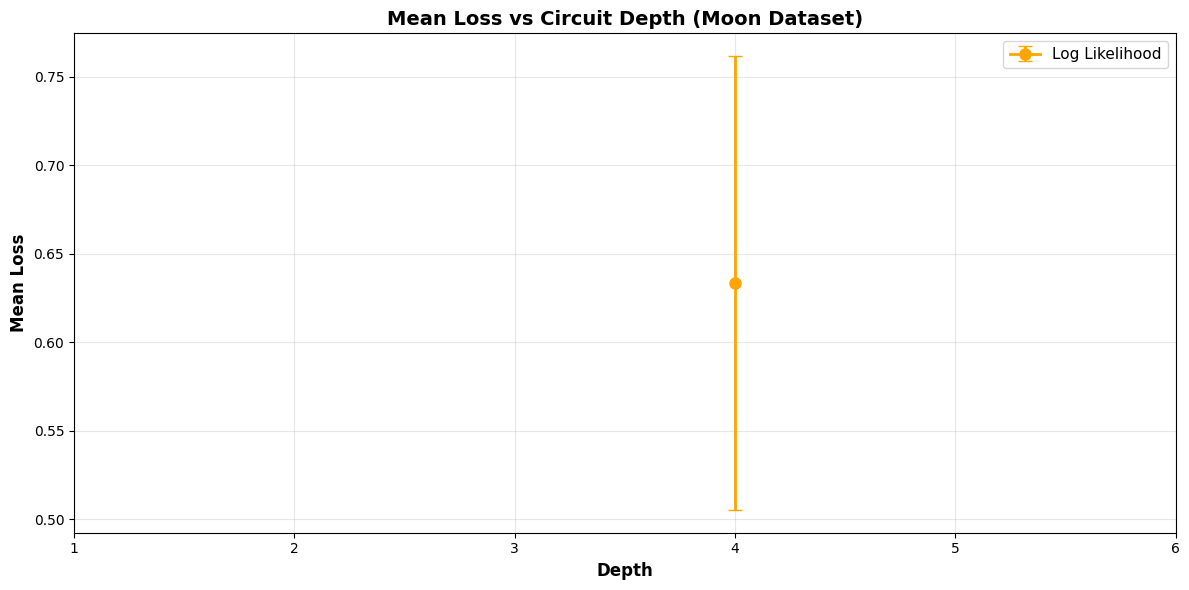

In [6]:
plt.figure(figsize=(12, 6))

for loss_type in loss_types:
    valid_depths = []
    mean_losses = []
    std_losses = []
    
    for depth in depths:
        if loss_type in stats[depth] and stats[depth][loss_type]['mean_loss'] is not None:
            valid_depths.append(depth)
            mean_losses.append(stats[depth][loss_type]['mean_loss'])
            std_losses.append(stats[depth][loss_type]['std_loss'])
    
    if mean_losses:
        plt.errorbar(valid_depths, mean_losses, yerr=std_losses, 
                    marker='o', linestyle='-', linewidth=2, markersize=8, capsize=5,
                    label=labels[loss_type], color=colors[loss_type])

plt.xlabel('Depth', fontsize=12, fontweight='bold')
plt.ylabel('Mean Loss', fontsize=12, fontweight='bold')
plt.title('Mean Loss vs Circuit Depth (Moon Dataset)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xticks(depths)
plt.tight_layout()
plt.show()

## 4. Visualize Train and Test Accuracy vs Depth

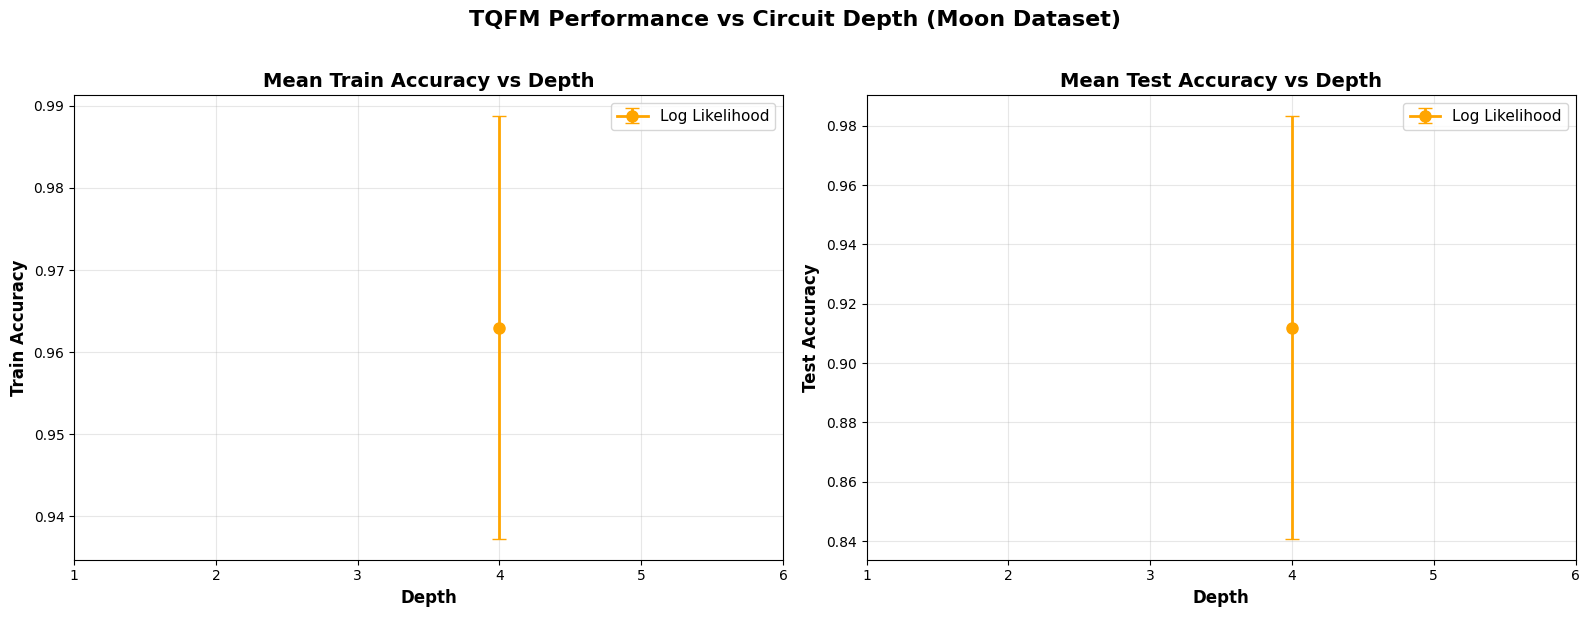

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left: Train Accuracy
for loss_type in loss_types:
    valid_depths = []
    mean_accs = []
    std_accs = []
    
    for depth in depths:
        if loss_type in stats[depth] and stats[depth][loss_type]['mean_train_acc'] is not None:
            valid_depths.append(depth)
            mean_accs.append(stats[depth][loss_type]['mean_train_acc'])
            std_accs.append(stats[depth][loss_type]['std_train_acc'])
    
    if mean_accs:
        ax1.errorbar(valid_depths, mean_accs, yerr=std_accs,
                    marker='o', linestyle='-', linewidth=2, markersize=8, capsize=5,
                    label=labels[loss_type], color=colors[loss_type])

ax1.set_xlabel('Depth', fontsize=12, fontweight='bold')
ax1.set_ylabel('Train Accuracy', fontsize=12, fontweight='bold')
ax1.set_title('Mean Train Accuracy vs Depth', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(depths)

# Right: Test Accuracy
for loss_type in loss_types:
    valid_depths = []
    mean_accs = []
    std_accs = []
    
    for depth in depths:
        if loss_type in stats[depth] and stats[depth][loss_type]['mean_test_acc'] is not None:
            valid_depths.append(depth)
            mean_accs.append(stats[depth][loss_type]['mean_test_acc'])
            std_accs.append(stats[depth][loss_type]['std_test_acc'])
    
    if mean_accs:
        ax2.errorbar(valid_depths, mean_accs, yerr=std_accs,
                    marker='o', linestyle='-', linewidth=2, markersize=8, capsize=5,
                    label=labels[loss_type], color=colors[loss_type])

ax2.set_xlabel('Depth', fontsize=12, fontweight='bold')
ax2.set_ylabel('Test Accuracy', fontsize=12, fontweight='bold')
ax2.set_title('Mean Test Accuracy vs Depth', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.set_xticks(depths)


plt.suptitle('TQFM Performance vs Circuit Depth (Moon Dataset)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 5. Loss Trajectories (All Runs)

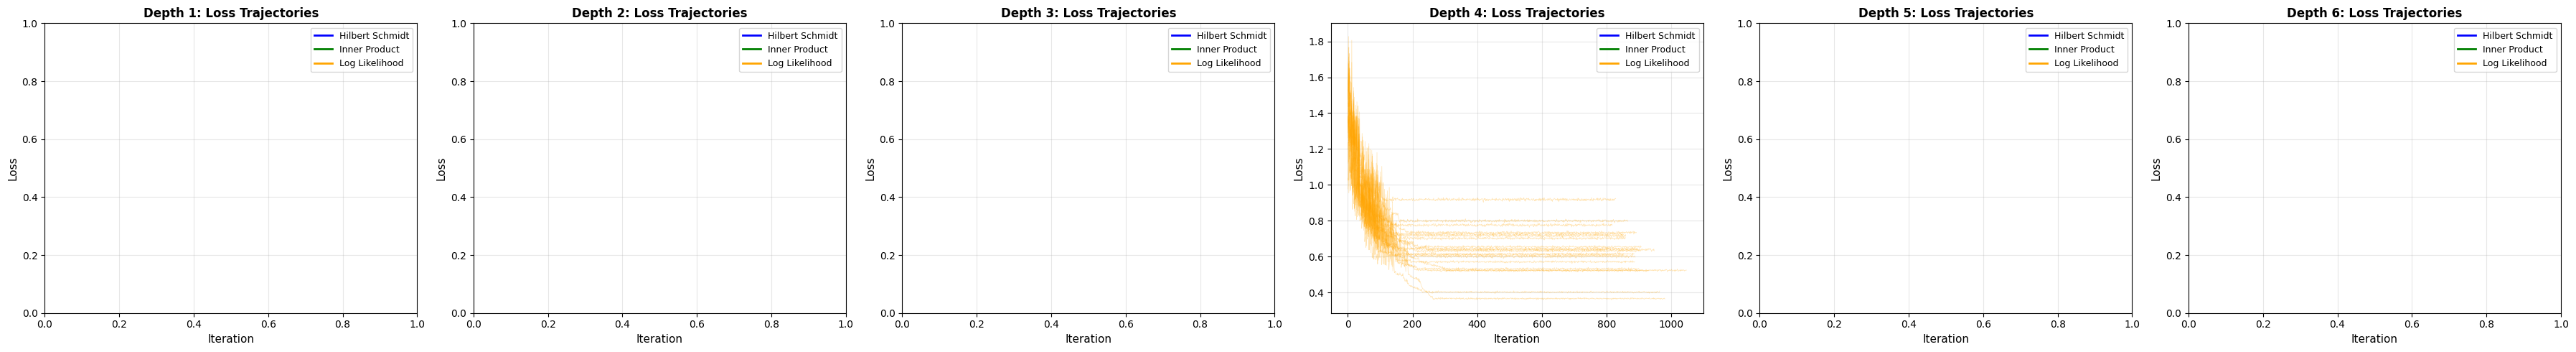

In [8]:
fig, axes = plt.subplots(1, len(depths), figsize=(6*len(depths), 5))
if len(depths) == 1:
    axes = [axes]

for idx, depth in enumerate(depths):
    ax = axes[idx]
    
    for loss_type in loss_types:
        runs = depth_results[depth][loss_type]
        for run in runs:
            if run['loss_history']:
                ax.plot(run['loss_history'], alpha=0.3, color=colors[loss_type], linewidth=0.5)
    
    # Add legend
    handles = [plt.Line2D([0], [0], color=colors[lt], lw=2) for lt in loss_types]
    ax.legend(handles, [labels[lt] for lt in loss_types], fontsize=9)
    
    ax.set_xlabel('Iteration', fontsize=11)
    ax.set_ylabel('Loss', fontsize=11)
    ax.set_title(f'Depth {depth}: Loss Trajectories', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Mean Loss Trajectory with Std

C:\Users\Nguyen Dinh Quyen\AppData\Local\Temp\ipykernel_30908\3105786844.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=9)


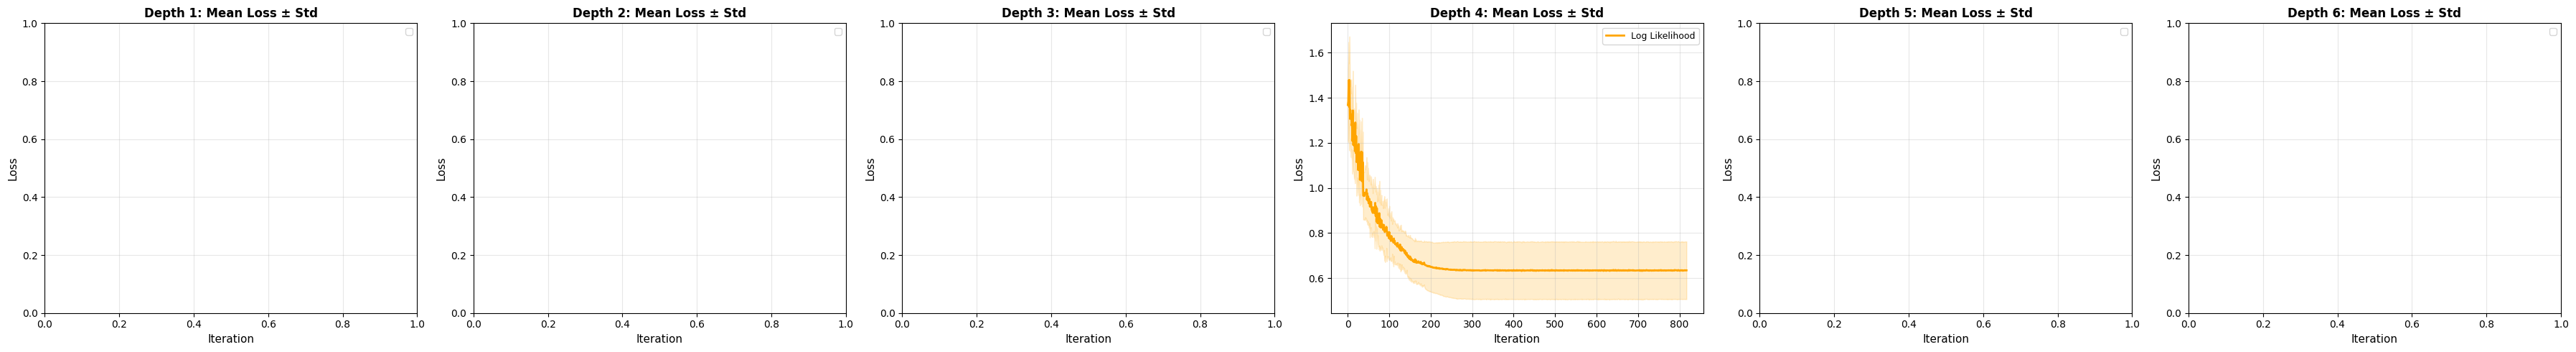

In [9]:
fig, axes = plt.subplots(1, len(depths), figsize=(6*len(depths), 5))
if len(depths) == 1:
    axes = [axes]

for idx, depth in enumerate(depths):
    ax = axes[idx]
    
    for loss_type in loss_types:
        runs = depth_results[depth][loss_type]
        histories = [r['loss_history'] for r in runs if r['loss_history']]
        
        if not histories:
            continue
        
        # Find minimum length
        min_len = min(len(h) for h in histories)
        truncated = np.array([h[:min_len] for h in histories])
        
        mean_traj = np.mean(truncated, axis=0)
        std_traj = np.std(truncated, axis=0)
        
        ax.plot(mean_traj, color=colors[loss_type], linewidth=2, label=labels[loss_type])
        ax.fill_between(range(len(mean_traj)), 
                       mean_traj - std_traj, mean_traj + std_traj,
                       color=colors[loss_type], alpha=0.2)
    
    ax.set_xlabel('Iteration', fontsize=11)
    ax.set_ylabel('Loss', fontsize=11)
    ax.set_title(f'Depth {depth}: Mean Loss ± Std', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Box Plot Comparison

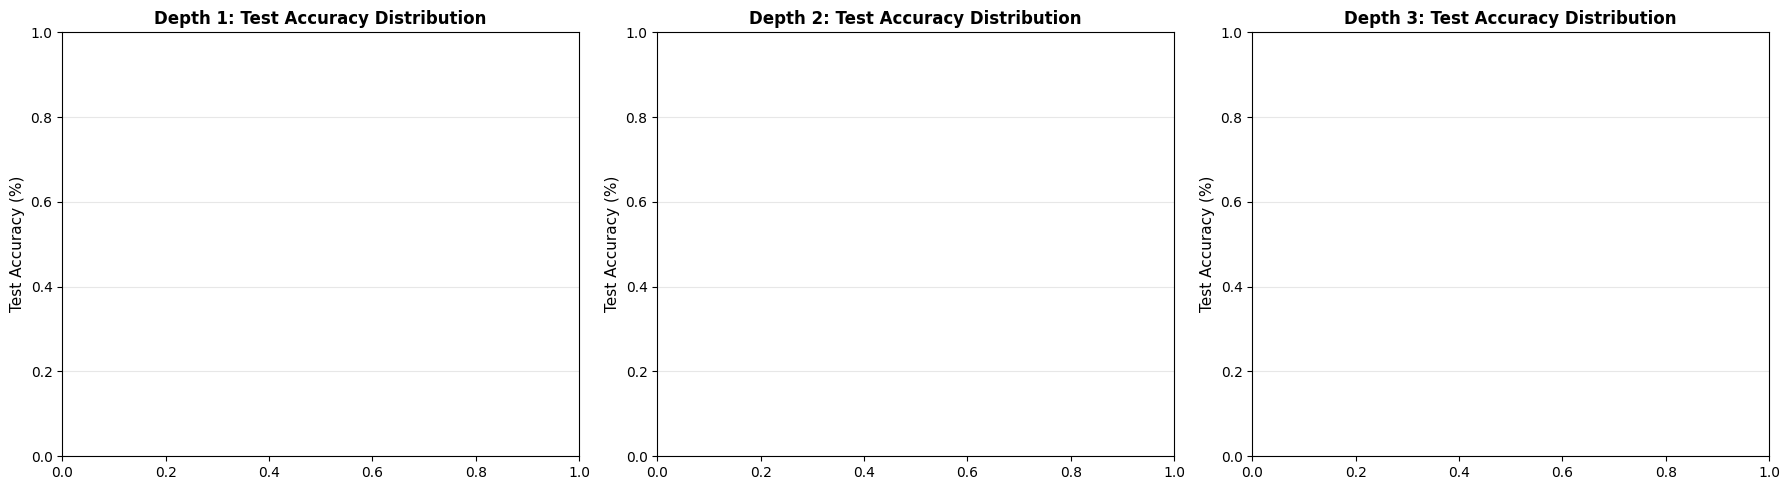

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Prepare data for box plots
for idx, depth in enumerate(depths[:3]):  # Show first 3 depths
    ax = axes[idx] if len(depths) >= 3 else axes[idx % len(axes)]
    
    data_for_plot = []
    labels_for_plot = []
    
    for loss_type in loss_types:
        runs = depth_results[depth][loss_type]
        test_accs = []
        
        # Get test accuracies from JSON
        for json_data in json_results[depth]:
            if 'test_accuracies' in json_data and json_data['test_accuracies']:
                test_acc = json_data['test_accuracies'].get(loss_type)
                if test_acc is not None:
                    test_accs.append(test_acc * 100)  # Convert to percentage
        
        if test_accs:
            data_for_plot.append(test_accs)
            labels_for_plot.append(labels[loss_type])
    
    if data_for_plot:
        bp = ax.boxplot(data_for_plot, labels=labels_for_plot, patch_artist=True)
        
        # Color the boxes
        for patch, loss_type in zip(bp['boxes'], loss_types[:len(bp['boxes'])]):
            patch.set_facecolor(colors[loss_type])
            patch.set_alpha(0.6)
    
    ax.set_ylabel('Test Accuracy (%)', fontsize=11)
    ax.set_title(f'Depth {depth}: Test Accuracy Distribution', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 8. Summary Table

In [11]:
# Create comprehensive summary table
print("="*100)
print("COMPREHENSIVE RESULTS SUMMARY")
print("="*100)

for depth in depths:
    print(f"\nDepth {depth}:")
    print("-"*80)
    print(f"{'Loss Function':<25} | {'Train Acc':<20} | {'Test Acc':<20} | {'Final Loss':<15} | Runs")
    print("-"*80)
    
    for loss_type in loss_types:
        if loss_type in stats[depth]:
            s = stats[depth][loss_type]
            
            train_str = f"{s['mean_train_acc']:.2f} ± {s['std_train_acc']:.2f}" if s['mean_train_acc'] else 'N/A'
            test_str = f"{s['mean_test_acc']:.2f} ± {s['std_test_acc']:.2f}" if s['mean_test_acc'] else 'N/A'
            loss_str = f"{s['mean_loss']:.4f} ± {s['std_loss']:.4f}" if s['mean_loss'] else 'N/A'
            
            print(f"{labels[loss_type]:<25} | {train_str:<20} | {test_str:<20} | {loss_str:<15} | {s['n_runs']}")
        else:
            print(f"{labels[loss_type]:<25} | No data")

print("\n" + "="*100)

COMPREHENSIVE RESULTS SUMMARY

Depth 1:
--------------------------------------------------------------------------------
Loss Function             | Train Acc            | Test Acc             | Final Loss      | Runs
--------------------------------------------------------------------------------
Hilbert Schmidt           | No data
Inner Product             | No data
Log Likelihood            | No data

Depth 2:
--------------------------------------------------------------------------------
Loss Function             | Train Acc            | Test Acc             | Final Loss      | Runs
--------------------------------------------------------------------------------
Hilbert Schmidt           | No data
Inner Product             | No data
Log Likelihood            | No data

Depth 3:
--------------------------------------------------------------------------------
Loss Function             | Train Acc            | Test Acc             | Final Loss      | Runs
----------------------------